In [30]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import GridSearchCV

In [31]:
data = pd.read_csv('Admission_Predict.csv', index_col=0)
data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
Serial No.,,,,,,,,
1,337,118,4,4.5,4.5,9.65,1,0.92
2,324,107,4,4.0,4.5,8.87,1,0.76
3,316,104,3,3.0,3.5,8.00,1,0.72
4,322,110,3,3.5,2.5,8.67,1,0.80
5,314,103,2,2.0,3.0,8.21,0,0.65
...,...,...,...,...,...,...,...,...
396,324,110,3,3.5,3.5,9.04,1,0.82
397,325,107,3,3.0,3.5,9.11,1,0.84
398,330,116,4,5.0,4.5,9.45,1,0.91


In [32]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 1 to 400
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          400 non-null    int64  
 1   TOEFL Score        400 non-null    int64  
 2   University Rating  400 non-null    int64  
 3   SOP                400 non-null    float64
 4   LOR                400 non-null    float64
 5   CGPA               400 non-null    float64
 6   Research           400 non-null    int64  
 7   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.1 KB


In [33]:
print(data['Research'].value_counts()) # categorical feature
data['GRE/TOEFL'] = data['GRE Score']/data['TOEFL Score']
data

Research
1    219
0    181
Name: count, dtype: int64


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,GRE/TOEFL
Serial No.,,,,,,,,,
1,337,118,4,4.5,4.5,9.65,1,0.92,2.855932
2,324,107,4,4.0,4.5,8.87,1,0.76,3.028037
3,316,104,3,3.0,3.5,8.00,1,0.72,3.038462
4,322,110,3,3.5,2.5,8.67,1,0.80,2.927273
5,314,103,2,2.0,3.0,8.21,0,0.65,3.048544
...,...,...,...,...,...,...,...,...,...
396,324,110,3,3.5,3.5,9.04,1,0.82,2.945455
397,325,107,3,3.0,3.5,9.11,1,0.84,3.037383
398,330,116,4,5.0,4.5,9.45,1,0.91,2.844828


<Axes: >

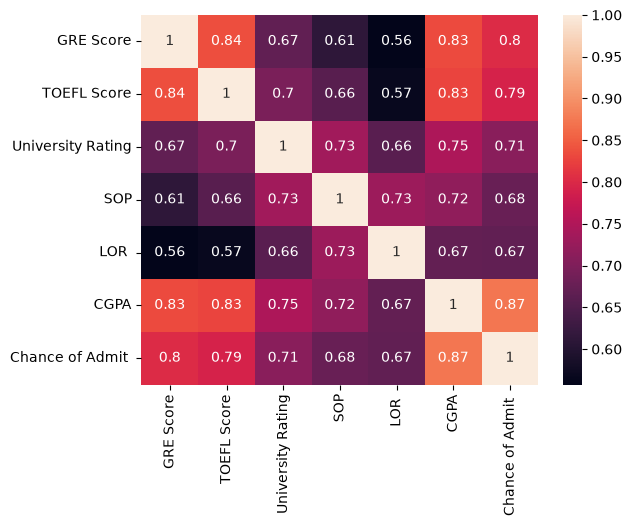

In [34]:
# we're going to check now if any of numerical features correlate
sns.heatmap(data[['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Chance of Admit ']].corr(), annot=True)

In [35]:
# we can see that GRE score and TOEFL, GRE and CGPA, TOEFL and CGPA correlate
X = data.drop(columns=['Chance of Admit ', 'GRE/TOEFL'])
y = data['Chance of Admit ']
scaler = StandardScaler()
scaler.fit(X)
data_scaled = scaler.transform(X)

In [39]:
data_train, data_test, target_train, target_test = train_test_split(data_scaled, y, test_size=0.2, random_state=42)
# x_train, x_val, y_train, y_val = train_test_split(data_train, target_train, test_size=0.2, random_state=42)

In [40]:
reg = SGDRegressor()
reg.fit(data_train, target_train)
print(reg.intercept_, reg.coef_)

[0.72364594] [0.02754781 0.02724061 0.0076449  0.00090892 0.01814718 0.04645396
 0.00918648]


In [19]:
reg.score(data_train, y_train)

0.8049049298888308

In [42]:
parameters = {'penalty':('l2', 'l1', 'elasticnet'), 'l1_ratio':[0, 0.25, 0.5,  0.75, 1], 'alpha':[ 1e-2, 0.1, 1, 10, 100]}
clf = GridSearchCV(reg, parameters) 
clf.fit(data_train, target_train)
clf.best_params_

{'alpha': 0.01, 'l1_ratio': 0, 'penalty': 'l2'}

In [43]:
final_model = clf.best_estimator_
final_model.score(data_train, target_train)

0.7888525258407186

In [44]:
final_model.score(data_test, target_test)

0.8126213314900963

In [46]:
final_model.coef_ # as we can see the most important features are CGPA, GRE, TOEFL, and LOR

array([ 0.0303886 ,  0.02499098,  0.01199144, -0.00224436,  0.01920299,
        0.04480113,  0.00844806])